# 00 · Intraday backtests

`tactical-cube` simulates strategies that decide within the day. A strategy sees one day's bars
from `nanoprobe-array` and returns target weights at bar ends; the cube fills them a bar or more
later (or in the official auctions), caps each fill at a share of the bar's volume, charges
intraday costs, and reports daily returns in `unimatrix-zero`'s format. Design:
`docs/decisions/0014-intraday.md` (phase 2). The studies themselves live in
`projects/assimilation-trials`.

1. one day, fill by fill
2. when in the day you trade: the cost of the open
3. participation: a thin name at size
4. overnight holds: splits, dividends and the daily engine
5. the look-ahead check
6. where a day's P&L comes from

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import polars as pl
from nanoprobe_array import Nanoprobe
from subspace_probe import style, timed
from tactical_cube import NO_INTRADAY_COSTS, Cube, IntradayCosts, LookaheadError, check_lookahead
from unimatrix_zero import Engine

style()
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(150)
p = Nanoprobe()
cube = Cube(probe=p)
NY = "America/New_York"
def hhmm(c):
    return pl.col(c).dt.convert_time_zone(NY).dt.strftime("%H:%M")

def at(minutes_from_open: int, weight: float = 1.0):
    """A strategy: hold `weight` of every name in the bars from `minutes_from_open` to the close."""
    def strategy(day, bars):
        b = bars.filter(pl.col("minutes_from_open") == minutes_from_open)
        return b.select("bar_end", "security_id", weight=pl.lit(weight / max(b.height, 1)))
    return strategy

## 1 · One day, fill by fill

Buy SPY with the whole capital at 10:00 and hold it to the close. The decision is at the end of
the 09:55-10:00 bar; with `lag=1` the order fills in the next bar (10:00-10:05) at its VWAP, and
`flat_by="close"` sells in the official closing auction. A bar's P&L is the position times the
change in mark plus the trade times (mark - fill price), so the gap between the fill and the
bar's close counts as slippage.

In [2]:
D = date(2025, 3, 10)
costs = IntradayCosts(aum=1e6)
bt = cube.run(at(30), D, D, tickers=["SPY"], costs=costs)
bt.fills.select("kind", hhmm("decision_time").fill_null("flat_by").alias("decided"), hhmm("fill_time").alias("filled"), "units",
                "price", "decision_price", "slippage_bps", "spread_bps", "impact_bps", "commission_bps", "participation")

kind,decided,filled,units,price,decision_price,slippage_bps,spread_bps,impact_bps,commission_bps,participation
str,str,str,f64,f64,f64,f64,f64,f64,f64,f64
"""bar""","""10:00""","""10:05""",1762.549351,566.343359,567.36,-17.918799,0.6,0.509844,0.0618,0.001665
"""close_auction""","""flat_by""","""16:00""",-1762.549351,560.58,560.58,-0.0,0.0,0.507244,0.062435,null


In [3]:
bt.daily.select("date", "gross", "cost", "net", "turnover", "gross_exposure", "fills")

date,gross,cost,net,turnover,gross_exposure,fills
date,f64,f64,f64,f64,f64,i64
2025-03-10,-0.010158,0.000173,-0.010331,1.986258,0.91486,2


`lag=2` waits one more bar, and `fill="open"` takes the fill bar's open instead of its VWAP.

In [4]:
rows = []
for lag in (1, 2, 3):
    for fill in ("vwap", "open", "close"):
        b = cube.run(at(30), D, D, tickers=["SPY"], lag=lag, fill=fill, costs=NO_INTRADAY_COSTS)
        f = b.fills.filter(pl.col("kind") == "bar")
        rows.append({"lag": lag, "fill": fill, "filled_in": f.select(hhmm("fill_time"))[0, 0], "price": f["price"][0],
                     "slippage_bps": f["slippage_bps"][0], "day_gross_bps": b.daily["gross"][0] * 1e4})
pl.DataFrame(rows)

lag,fill,filled_in,price,slippage_bps,day_gross_bps
i64,str,str,f64,f64,f64
1,"""vwap""","""10:05""",566.343359,-17.918799,-101.582047
1,"""open""","""10:05""",567.32,-0.70502,-118.795826
1,"""close""","""10:05""",565.9,-25.733221,-93.767625
2,"""vwap""","""10:10""",566.002428,-23.927879,-95.572967
2,"""open""","""10:10""",565.94,-25.028201,-94.472645
2,"""close""","""10:10""",565.845,-26.702623,-92.798223
3,"""vwap""","""10:15""",566.258148,-19.42068,-100.080166
3,"""open""","""10:15""",565.87,-26.261985,-93.238861
3,"""close""","""10:15""",566.36,-17.625494,-101.875353


## 2 · When in the day you trade

Half-spreads are widest just after the open and the closing auction has none. The cost model
multiplies the fitted daily half-spread by a profile measured on trades and quotes (decision
0017): 3.7× in the first minute, 2.6× to 5, 1.75× to 15, 1.4× to 30, 1.2× to 60, then about 1
and falling to 0.6× at the close. Enter SPY and a mid cap at different times through 2024 and
compare the cost per unit traded. SPY sits at the stock fit's 0.5 bp floor; its measured spread
is about 0.12 bp and flat through the day, so studies of index ETFs pass that number with no
profile (as `projects/assimilation-trials` does).

In [5]:
rows = []
for ticker in ("SPY", "ETSY"):
    for m in (5, 15, 30, 120, 360):
        b = cube.run(at(m), "2024-01-02", "2024-12-31", tickers=[ticker], costs=costs, check_lookahead=0)
        s = b.fill_stats().filter(pl.col("kind") == "bar")
        rows.append({"ticker": ticker, "enter_after_min": m, "spread_bps": s["spread_bps"][0],
                     "impact_bps": s["impact_bps"][0], "commission_bps": s["commission_bps"][0],
                     "slippage_bps": s["slippage_bps"][0],
                     "close_auction_bps": b.fill_stats().filter(pl.col("kind") == "close_auction")
                     .select(pl.sum_horizontal("spread_bps", "impact_bps", "commission_bps"))[0, 0]})
pl.DataFrame(rows)

ticker,enter_after_min,spread_bps,impact_bps,commission_bps,slippage_bps,close_auction_bps
str,i64,f64,f64,f64,f64,f64
"""SPY""",5,0.875,0.442038,0.064955,-0.538842,0.50702
"""SPY""",15,0.695,0.442052,0.064958,0.021896,0.507044
"""SPY""",30,0.6,0.442055,0.064954,0.017845,0.507028
"""SPY""",120,0.46,0.442052,0.064957,-0.059413,0.507042
"""SPY""",360,0.35,0.441992,0.065012,-0.759754,0.507015
"""ETSY""",5,4.110112,18.140376,0.588614,3.358165,18.697059
"""ETSY""",15,3.597966,18.094587,0.58774,0.684636,18.694987
"""ETSY""",30,3.253726,18.120619,0.587716,3.939888,18.695826
"""ETSY""",120,2.53467,18.083685,0.591082,-0.633271,18.690494


## 3 · Participation: a thin name at size

With an AUM each fill takes at most 10% of the bar's share volume; the rest keeps working in the
following bars (and never on an empty bar). Buying $5M of a small cap at 10:00 takes many bars,
and some days it is not done by the close. Impact is charged on the whole order, not on each
fill, so splitting an order does not make it cheaper; the $0.35 commission minimum is per order.

In [6]:
big = IntradayCosts(aum=5e6)
bt = cube.run(at(30), "2024-01-02", "2024-03-28", tickers=["CRMT"], costs=big, check_lookahead=0)
f = bt.fills.filter(pl.col("kind") == "bar")
per_day = f.group_by("date").agg(pl.len().alias("fills"), pl.col("wait_bars").max().alias("last_fill_bar"),
                                 pl.col("participation").max().alias("max_participation"),
                                 (pl.col("units") * pl.col("price")).sum().alias("bought"))
print(f"{per_day.height} days; median {per_day['fills'].median():.0f} fills to build the position;"
      f" median bought ${per_day['bought'].median():,.0f} of $5,000,000")
per_day.sort("date").head(8)

61 days; median 50 fills to build the position; median bought $353,793 of $5,000,000


date,fills,last_fill_bar,max_participation,bought
date,u32,i32,f64,f64
2024-01-02,47,71,0.1,619843.812427
2024-01-03,44,71,0.1,460955.990013
2024-01-04,45,71,0.1,294716.918463
2024-01-05,46,71,0.1,310145.266607
2024-01-08,42,71,0.1,269826.06141
2024-01-09,35,71,0.1,231738.675553
2024-01-10,51,71,0.1,206270.215807
2024-01-11,50,71,0.1,359986.291783


In [7]:
bt.unfilled.group_by("reason").agg(pl.len().alias("orders"), (pl.col("done") / pl.col("wanted")).mean().alias("mean_share_done"))

reason,orders,mean_share_done
str,u32,f64
"""not filled by the end of the s…",61,0.098866


## 4 · Overnight holds

`flat_by=None` keeps positions overnight. They roll at `prev_close` (yesterday's close on
today's share basis), so a split moves nothing and a dividend is paid. Buy SPY, AAPL and NVDA
in the closing auction each day and hold: without costs this is buy and hold, and the daily
returns must equal those of `unimatrix-zero`'s daily engine, NVDA's 10-for-1 split on
2024-06-10 included. The check is exact when the weight actually held (the auction price over
the decision price) is used.

In [8]:
def hold(day, bars):
    b = bars.filter(pl.col("minutes_to_close") == 15)
    return b.select("bar_end", "security_id", weight=pl.lit(1 / 3), auction=pl.lit("close"))

with timed("a year, three names, held overnight"):
    bt = cube.run(hold, "2024-01-02", "2024-12-31", tickers=["SPY", "AAPL", "NVDA"], flat_by=None,
                  costs=NO_INTRADAY_COSTS)
r = Engine().returns(bt.by_security["security_id"].unique().to_list(), "2024-01-02", "2024-12-31")
f = bt.fills.filter(pl.col("kind") == "close_auction").select(
    "security_id", "date", w=(1 / 3) * pl.col("price") / pl.col("decision_price"))
cal = sorted(bt.daily["date"].to_list())
f = f.with_columns(date=pl.col("date").replace_strict(dict(zip(cal[:-1], cal[1:])), default=None)).drop_nulls()
exact = f.join(r, on=["security_id", "date"]).group_by("date").agg((pl.col("w") * pl.col("ret")).sum().alias("engine"))
k = bt.daily.select("date", "gross").join(exact, on="date").sort("date")
print(f"{k.height} days compared; max |tactical-cube - daily engine| = {(k['gross'] - k['engine']).abs().max():.1e}")
k.filter(pl.col("date").is_between(date(2024, 6, 6), date(2024, 6, 11)))

a year, three names, held overnight: 2.93 s


251 days compared; max |tactical-cube - daily engine| = 1.7e-16


date,gross,engine
date,f64,f64
2024-06-06,-0.00631,-0.00631
2024-06-07,0.003409,0.003409
2024-06-10,-0.002876,-0.002876
2024-06-11,0.022687,0.022687


## 5 · The look-ahead check

Before a run, the cube re-runs the strategy on the first days' bars cut at 25, 50 and 75% of the
session. A target decided before a cut must not change when the bars after it are removed. A
strategy that peeks at the day's last close fails at once.

In [9]:
def cheat(day, bars):
    """At 10:00, size SPY by its move from 10:00 to the day's last bar (it cannot know that yet)."""
    b = bars.filter(pl.col("minutes_from_open") == 30)
    move = bars["close"].last() / b["close"][0] - 1
    return b.select("bar_end", "security_id", weight=pl.lit(max(-1.0, min(1.0, 100 * move))))

_, bars = next(p.days(D, D, tickers=["SPY"]))
check_lookahead(at(30), D, bars)
print("at(30): passes")
try:
    check_lookahead(cheat, D, bars)
except LookaheadError as e:
    print("cheat:", e)

at(30): passes
cheat: 2025-03-10: targets up to 2025-03-10 15:05:00+00:00 change when the bars after it are removed (1 rows with the whole day, 1 without). The strategy reads bars after its decision time (e.g. a whole-day max, the last close, or a feature shifted backwards).


## 6 · Where a day's P&L comes from

`by_time_of_day` adds up the P&L of each bar across days: here SPY held from 09:35 to the close,
every day since 2015.

SPY 2015-2026, from 09:35 to the close: 35.29 s


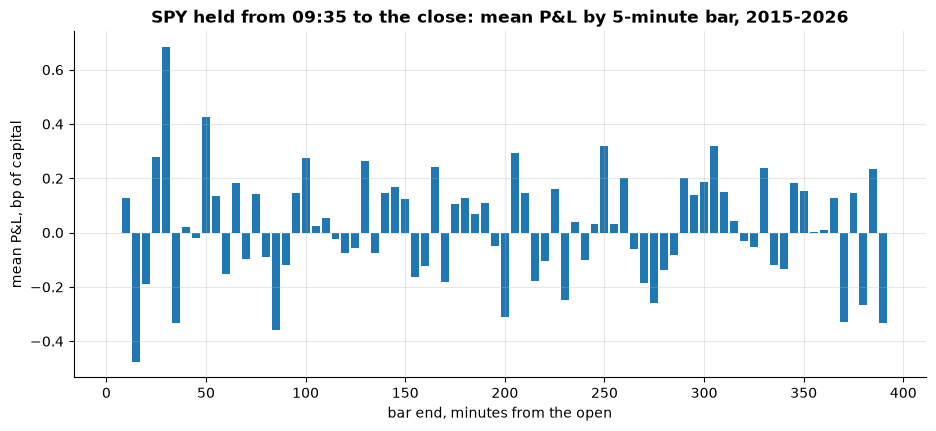

share of the gross P&L: first half hour 25%, last half hour -25%


series,ann_return,ann_vol,sharpe,t_stat,max_drawdown,cost_drag
str,f64,f64,f64,f64,f64,f64
"""net""",-0.019402,0.12766,-0.089764,-0.308422,-0.330745,0.056413
"""gross""",0.037011,0.127703,0.348313,1.196775,-0.276253,null


In [10]:
with timed("SPY 2015-2026, from 09:35 to the close"):
    bt = cube.run(at(5), "2015-01-02", "2026-10-30", tickers=["SPY"], costs=costs, check_lookahead=0)
tod = bt.by_time_of_day()
fig, ax = plt.subplots()
ax.bar(tod["minutes_from_open"], tod["mean_bp"], width=4)
ax.set_xlabel("bar end, minutes from the open")
ax.set_ylabel("mean P&L, bp of capital")
ax.set_title("SPY held from 09:35 to the close: mean P&L by 5-minute bar, 2015-2026")
plt.show()
first, last = tod.filter(pl.col("minutes_from_open") <= 30)["share"].sum(), tod.filter(pl.col("minutes_from_open") > 360)["share"].sum()
print(f"share of the gross P&L: first half hour {first:.0%}, last half hour {last:.0%}")
bt.summary().filter(pl.col("series").is_in(["gross", "net"])).select(
    "series", "ann_return", "ann_vol", "sharpe", "t_stat", "max_drawdown", "cost_drag")